In [4]:
import numpy as np
import pandas as pd

In [5]:
data = pd.read_csv('../Data_Output/C_data.csv')

data.columns = data.columns.str.strip()
data.head()

,date,expiry date,strike,maturity (years),rate,underlying,call option price,implied vol
0,04-Jan-2010,08-Jan-2010,80.0,0.010959,6.0,100.0,20.05260,0.281263
1,04-Jan-2010,08-Jan-2010,85.0,0.010959,6.0,100.0,15.05590,0.238420
2,04-Jan-2010,08-Jan-2010,90.0,0.010959,6.0,100.0,10.05920,0.225673
3,04-Jan-2010,08-Jan-2010,95.0,0.010959,6.0,100.0,5.06966,0.212739
4,04-Jan-2010,08-Jan-2010,100.0,0.010959,6.0,100.0,0.86685,0.199664


In [6]:
S = data.drop_duplicates(subset="date")[['date', 'underlying']]
S.head(10)

,date,underlying
0,04-Jan-2010,100.0000
142,05-Jan-2010,100.3150
286,06-Jan-2010,98.2508
430,07-Jan-2010,95.0312
574,08-Jan-2010,93.5638
718,11-Jan-2010,93.5350
862,12-Jan-2010,94.0621
1005,13-Jan-2010,92.6887
1146,14-Jan-2010,92.1590
1289,15-Jan-2010,92.4499


In [7]:
C = data[['date', 'expiry date', 'strike', 'call option price']].copy()
C.head()

,date,expiry date,strike,call option price
0,04-Jan-2010,08-Jan-2010,80.0,20.05260
1,04-Jan-2010,08-Jan-2010,85.0,15.05590
2,04-Jan-2010,08-Jan-2010,90.0,10.05920
3,04-Jan-2010,08-Jan-2010,95.0,5.06966
4,04-Jan-2010,08-Jan-2010,100.0,0.86685


In [8]:
imp_vol = data[['date', 'expiry date', 'strike', 'implied vol']].copy()
imp_vol.head()

,date,expiry date,strike,implied vol
0,04-Jan-2010,08-Jan-2010,80.0,0.281263
1,04-Jan-2010,08-Jan-2010,85.0,0.238420
2,04-Jan-2010,08-Jan-2010,90.0,0.225673
3,04-Jan-2010,08-Jan-2010,95.0,0.212739
4,04-Jan-2010,08-Jan-2010,100.0,0.199664


In [9]:
r = data.drop_duplicates(subset="date")[['date', 'rate']]
r.head(10)

,date,rate
0,04-Jan-2010,6.00000
142,05-Jan-2010,6.02011
286,06-Jan-2010,6.01196
430,07-Jan-2010,6.02608
574,08-Jan-2010,6.00833
718,11-Jan-2010,6.01838
862,12-Jan-2010,6.02319
1005,13-Jan-2010,6.02798
1146,14-Jan-2010,6.03224
1289,15-Jan-2010,6.02649


In [10]:
import os
import pandas as pd

# Make sure dates are treated as actual dates for splitting
data = data.copy()
data["date_dt"] = pd.to_datetime(data["date"], format="%d-%b-%Y", errors="coerce")
data["expiry_dt"] = pd.to_datetime(data["expiry date"], format="%d-%b-%Y", errors="coerce")

# Sort by date
data = data.sort_values(["date_dt", "expiry_dt"]).reset_index(drop=True)

# Last 60 unique dates go to test
unique_dates = data["date_dt"].dropna().drop_duplicates().sort_values()
test_dates = unique_dates.iloc[-60:]
cutoff_date = test_dates.iloc[0]

train_data = data[data["date_dt"] < cutoff_date].copy()
test_data = data[data["date_dt"] >= cutoff_date].copy()

# Drop helper columns before saving
train_data = train_data.drop(columns=["date_dt", "expiry_dt"])
test_data = test_data.drop(columns=["date_dt", "expiry_dt"])

# Create output folders
train_dir = "../Data_Output/train"
test_dir = "../Data_Output/test"
os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

# Split into the same four files for each set
def save_split(split_data, out_dir):
    S = split_data.drop_duplicates(subset="date")[["date", "underlying"]]
    C = split_data[["date", "expiry date", "strike", "call option price"]].copy()
    imp_vol = split_data[["date", "expiry date", "strike", "implied vol"]].copy()
    r = split_data.drop_duplicates(subset="date")[["date", "rate"]]

    S.to_csv(os.path.join(out_dir, "S_path.csv"), index=False)
    C.to_csv(os.path.join(out_dir, "C_grid.csv"), index=False)
    imp_vol.to_csv(os.path.join(out_dir, "vol_grid.csv"), index=False)
    r.to_csv(os.path.join(out_dir, "r_path.csv"), index=False)

save_split(train_data, train_dir)
save_split(test_data, test_dir)

In [ ]:
# Split heston_params.csv using the same cutoff
heston = pd.read_csv("../Data_Output/heston_params.csv")
heston.columns = heston.columns.str.strip()

heston["date_dt"] = pd.to_datetime(heston["date"], format="%d-%b-%Y", errors="coerce")
heston = heston.sort_values("date_dt").reset_index(drop=True)

heston_train = heston[heston["date_dt"] < cutoff_date].copy()
heston_test = heston[heston["date_dt"] >= cutoff_date].copy()

heston_train = heston_train.drop(columns=["date_dt"])
heston_test = heston_test.drop(columns=["date_dt"])

heston_train.to_csv(os.path.join(train_dir, "heston_params.csv"), index=False)
heston_test.to_csv(os.path.join(test_dir, "heston_params.csv"), index=False)

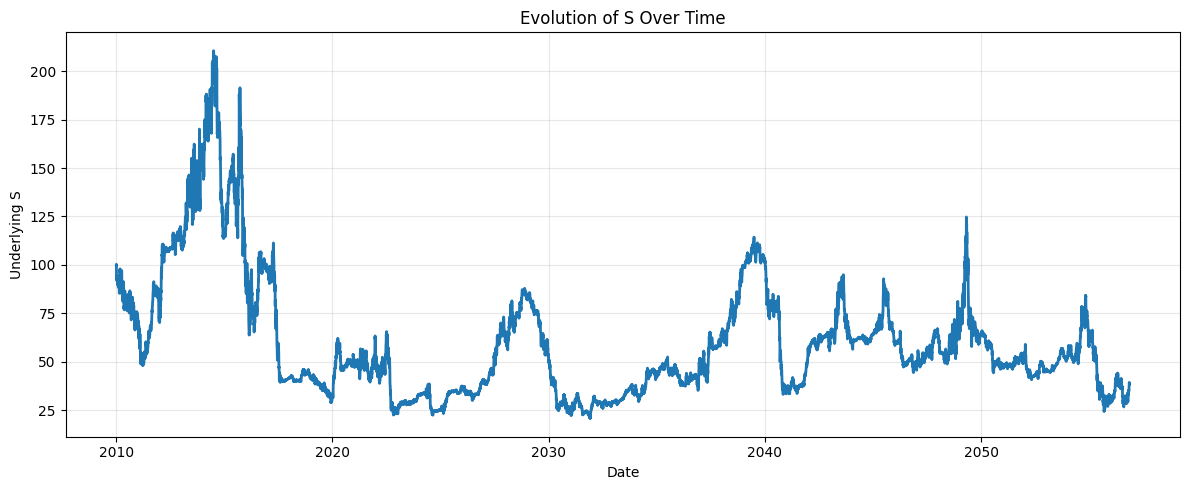

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

S_plot = data.drop_duplicates(subset="date")[["date", "underlying"]].copy()
S_plot["date_dt"] = pd.to_datetime(S_plot["date"], format="%d-%b-%Y", errors="coerce")
S_plot = S_plot.sort_values("date_dt")

plt.figure(figsize=(12, 5))
plt.plot(S_plot["date_dt"], S_plot["underlying"], linewidth=2)
plt.xlabel("Date")
plt.ylabel("Underlying S")
plt.title("Evolution of S Over Time")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()